# Milestone 3 EDA: the full history, 2015Q1–2026Q2 (46 quarters)

Exploration only; all logic lives in `src/`. Each chart is saved to
`docs/figures/` and followed by a short reading of what it shows.
Data: `data/processed/securities.duckdb` (`fund_quarter`, `positions`,
`stock_quarter`, `seed_positions`) plus the seed list's `style_guess`, which
is a weak label. The seed list is survivor-biased (funds known today), and so
are prices before about 2018 (chart 5), so cross-fund statistics for the
early years lean towards survivors.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data/processed/securities.duckdb"), read_only=True)

seed = (pl.read_csv(ROOT / "data/reference/seed_funds.csv")
        .select("fund_name", "style_guess").unique()
        .with_columns(pl.col("fund_name").str.to_lowercase().str.replace_all(r"[^a-z0-9]+", "_")
                      .str.strip_chars("_").alias("fund_id")))

FIRST_Q, LAST_Q = con.execute("SELECT min(quarter), max(quarter) FROM fund_quarter").fetchone()
N_Q = con.execute("SELECT count(DISTINCT quarter) FROM fund_quarter").fetchone()[0]
print(f"{FIRST_Q}–{LAST_Q}: {N_Q} quarters")

# Validated reference palette (light), slots in fixed order; checked with the
# dataviz skill's validate_palette.js: all gates pass on adjacent pairs.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
OTHER = "#b8b6b0"          # neutral bucket, deliberately not a series hue
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
SURFACE = "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a52a2a"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", [SURFACE, "#9ec5f0", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def save(fig, name):
    fig.savefig(FIG / name, dpi=160, bbox_inches="tight")
    print(f"saved docs/figures/{name}")

2015Q1–2026Q2: 46 quarters


## 1. Positions and turnover by style

Two measures on different scales, so two panels sharing the style axis
(never a dual axis). Each dot is one fund, summarised over every quarter it
filed: the median position count and the mean gross turnover. The bar marks
the style's median.

saved docs/figures/01_positions_turnover_by_style.png


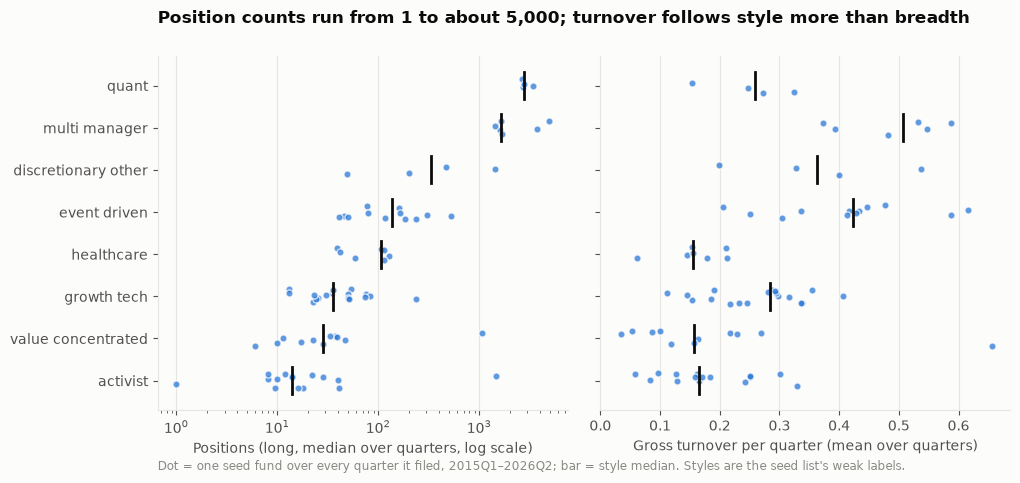

shape: (8, 7)
┌───────────────┬───────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ style_guess   ┆ funds ┆ median_posit ┆ median_gross ┆ median_turno ┆ min_position ┆ max_position │
│ ---           ┆ ---   ┆ ions         ┆ _turnover    ┆ ver          ┆ s            ┆ s            │
│ str           ┆ u32   ┆ ---          ┆ ---          ┆ ---          ┆ ---          ┆ ---          │
│               ┆       ┆ f64          ┆ f64          ┆ f64          ┆ f64          ┆ f64          │
╞═══════════════╪═══════╪══════════════╪══════════════╪══════════════╪══════════════╪══════════════╡
│ activist      ┆ 15    ┆ 14.0         ┆ 0.165        ┆ 0.103        ┆ 1.0          ┆ 1471.5       │
│ value_concent ┆ 11    ┆ 28.5         ┆ 0.157        ┆ 0.109        ┆ 6.0          ┆ 1065.0       │
│ rated         ┆       ┆              ┆              ┆              ┆              ┆              │
│ growth_tech   ┆ 18    ┆ 36.0         ┆ 0.284        ┆ 0.209        ┆ 13.0  

In [2]:
fq = con.execute("""
    SELECT fund_id, quarter, n_positions, turnover, gross_turnover FROM fund_quarter WHERE n_positions > 0
""").pl().join(seed.select("fund_id", "style_guess"), on="fund_id", how="left")
per_fund = fq.group_by("fund_id", "style_guess").agg(
    pl.col("n_positions").median().alias("n_positions"),
    pl.col("turnover").mean().alias("turnover"),
    pl.col("gross_turnover").mean().alias("gross_turnover"),
    pl.len().alias("quarters"),
)
order = (per_fund.group_by("style_guess").agg(pl.col("n_positions").median().alias("m"))
         .sort("m")["style_guess"].to_list())
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, col, label, log in [(axes[0], "n_positions", "Positions (long, median over quarters, log scale)", True),
                            (axes[1], "gross_turnover", "Gross turnover per quarter (mean over quarters)", False)]:
    for i, style in enumerate(order):
        v = per_fund.filter(pl.col("style_guess") == style)[col].drop_nulls().to_numpy()
        ax.scatter(v, i + rng.uniform(-0.18, 0.18, len(v)), s=26, color=SERIES[0], alpha=0.75,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        if len(v):
            ax.plot([np.median(v)] * 2, [i - 0.32, i + 0.32], color=INK, linewidth=2, zorder=4)
    ax.set_xscale("log" if log else "linear")
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), [s.replace("_", " ") for s in order])
axes[1].set_xlim(0, None)
fig.suptitle("Position counts run from 1 to about 5,000; turnover follows style more than breadth",
             x=0.125, ha="left", fontsize=12, fontweight="bold")
fig.text(0.125, -0.02, f"Dot = one seed fund over every quarter it filed, {FIRST_Q}–{LAST_Q}; bar = style median. "
         "Styles are the seed list's weak labels.", color=MUTED, fontsize=8.5)
save(fig, "01_positions_turnover_by_style.png")
plt.show()

print(per_fund.group_by("style_guess").agg(
    pl.len().alias("funds"), pl.col("n_positions").median().alias("median_positions"),
    pl.col("gross_turnover").median().round(3).alias("median_gross_turnover"),
    pl.col("turnover").median().round(3).alias("median_turnover"),
    pl.col("n_positions").min().alias("min_positions"), pl.col("n_positions").max().alias("max_positions"),
).sort("median_positions"))

**Reading.** Over the full history the style medians are: activists 14
positions, concentrated value 28, growth/tech 36, healthcare 106, event-driven
138, discretionary/other 336, multi-managers about 1,660 and quants about
2,750 (Citadel's book is the largest, a median of about 4,900). Turnover does
not simply rise with breadth: multi-managers trade the most (51% of gross book
a quarter) and event-driven funds 42% (deals close and the book refreshes),
but quants trade only 26% (AQR 15%), and healthcare (16%) trades like
activists and concentrated value funds (16%). The outliers show how weak the
labels are: Mantle Ridge holds one stock at a time; Ancora, labelled
activist, files about 1,500 positions because its 13F includes a wealth
management arm; Gotham, labelled value, holds about 1,000 names like a quant;
and Scion turns over 66% of its book a quarter. Within-style spread still
overlaps, so these two features alone won't recover the styles.

## 2. The most crowded stocks, and how crowding changed since 2015

Crowding = number of seed funds holding the stock long. Dumbbell from the
first quarter (gray) to the last (blue); top 20 by last-quarter crowding.
Share classes are kept separate (GOOG vs GOOGL), as in the `positions` table.
The number of filing funds differs between the two ends, and the 2015 end
counts only funds that survived to be on today's seed list.

saved docs/figures/02_most_crowded.png


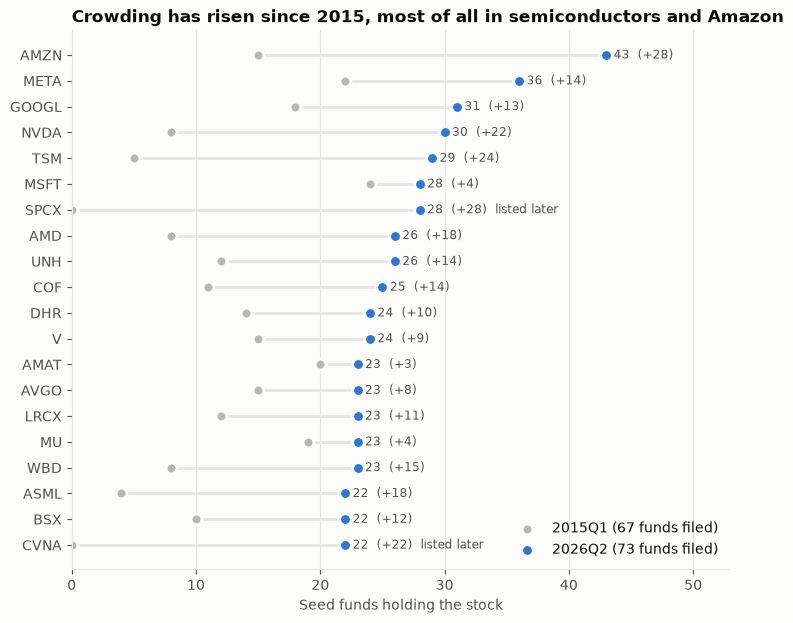

shape: (20, 5)
┌────────┬─────────┬─────────┬────────┬──────────────┐
│ symbol ┆ n_first ┆ n_funds ┆ change ┆ listed_later │
│ ---    ┆ ---     ┆ ---     ┆ ---    ┆ ---          │
│ str    ┆ u32     ┆ i64     ┆ i64    ┆ bool         │
╞════════╪═════════╪═════════╪════════╪══════════════╡
│ AMZN   ┆ 15      ┆ 43      ┆ 28     ┆ false        │
│ META   ┆ 22      ┆ 36      ┆ 14     ┆ false        │
│ GOOGL  ┆ 18      ┆ 31      ┆ 13     ┆ false        │
│ NVDA   ┆ 8       ┆ 30      ┆ 22     ┆ false        │
│ TSM    ┆ 5       ┆ 29      ┆ 24     ┆ false        │
│ …      ┆ …       ┆ …       ┆ …      ┆ …            │
│ MU     ┆ 19      ┆ 23      ┆ 4      ┆ false        │
│ WBD    ┆ 8       ┆ 23      ┆ 15     ┆ false        │
│ ASML   ┆ 4       ┆ 22      ┆ 18     ┆ false        │
│ BSX    ┆ 10      ┆ 22      ┆ 12     ┆ false        │
│ CVNA   ┆ 0       ┆ 22      ┆ 22     ┆ true         │
└────────┴─────────┴─────────┴────────┴──────────────┘
shape: (10, 3)
┌────────┬─────────┬─────────┐
│ sy

In [3]:
crowd = con.execute("""
    SELECT security_key AS symbol, quarter, count(DISTINCT fund_id) AS n_funds
    FROM positions WHERE NOT is_option AND security_class IN ('common', 'adr')
    GROUP BY ALL
""").pl()
# Corporate events since 2015 changed some CUSIPs, so the 2015 holding sits
# under another key: Google -> Alphabet (class A, 38259P508; class C, 38259P706),
# Avago -> Broadcom (Y0486S104), Discovery -> Warner Bros. Discovery (A and C).
PREDECESSORS = {"8888000D": "GOOGL", "9999000D": "GOOG", "1373183D": "AVGO", "DISCA": "WBD", "DISCK": "WBD"}
crowd_first = con.execute("""
    SELECT security_key AS symbol, fund_id FROM positions
    WHERE NOT is_option AND security_class IN ('common', 'adr') AND quarter = ?
""", [FIRST_Q]).pl().with_columns(pl.col("symbol").replace(PREDECESSORS))
first = crowd_first.group_by("symbol").agg(pl.col("fund_id").n_unique().alias("n_funds"))
# first trading day on our price source, to tell "listed later" from "nobody held it"
listed = con.execute("SELECT symbol, min(date) AS first_date FROM prices_daily GROUP BY 1").pl()
first_q_end = con.execute(f"SELECT last_day(make_date({FIRST_Q[:4]}, {int(FIRST_Q[-1]) * 3}, 1))").fetchone()[0]
last = crowd.filter(pl.col("quarter") == LAST_Q)
top = (last.sort("n_funds", "symbol", descending=[True, False]).head(20)   # symbol breaks ties deterministically
       .join(first.select("symbol", pl.col("n_funds").alias("n_first")), on="symbol", how="left")
       .join(listed, on="symbol", how="left")
       .with_columns(pl.col("n_first").fill_null(0),
                     (pl.col("n_funds") - pl.col("n_first").fill_null(0)).alias("change"),
                     (pl.col("first_date") > first_q_end).fill_null(False).alias("listed_later"))
       .sort("n_funds"))
n_filers = dict(con.execute("""
    SELECT quarter, count(DISTINCT fund_id) FROM fund_quarter WHERE n_positions > 0 GROUP BY 1
""").fetchall())

fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(top))
ax.hlines(y, top["n_first"], top["n_funds"], color=GRID, linewidth=2, zorder=1)
ax.scatter(top["n_first"], y, s=60, color=OTHER, edgecolor=SURFACE, linewidth=2, zorder=2,
           label=f"{FIRST_Q} ({n_filers[FIRST_Q]} funds filed)")
ax.scatter(top["n_funds"], y, s=70, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3,
           label=f"{LAST_Q} ({n_filers[LAST_Q]} funds filed)")
for yi, (n, ch, n0, later) in enumerate(zip(top["n_funds"], top["change"], top["n_first"], top["listed_later"])):
    note = "  listed later" if later else ""   # zero holders before listing is not "uncrowded"
    ax.text(max(n, n0) + 0.6, yi, f"{n}  ({ch:+d}){note}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, top["symbol"].to_list())
ax.set_xlabel("Seed funds holding the stock")
ax.set_xlim(0, top["n_funds"].max() + 10)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Crowding has risen since 2015, most of all in semiconductors and Amazon")
save(fig, "02_most_crowded.png")
plt.show()
print(top.sort("n_funds", descending=True).select("symbol", "n_first", "n_funds", "change", "listed_later"))
print(crowd.filter(pl.col("quarter") == FIRST_Q).sort("n_funds", descending=True).head(10))

**Reading.** In 2015Q1 the most widely held stock was Actavis
(30 of 67 funds), then Microsoft (24), DirecTV (22, a merger-arb trade), Illumina and
Facebook (22); of that top ten only Microsoft and Meta are still in the top
20. By 2026Q2 Amazon leads with 43 of 73 funds, and every name in today's top
20 has more holders than in 2015. The biggest gains are in Amazon (+28) and
semiconductors: TSMC +24, Nvidia +22, AMD and ASML +18, Lam +11; Microsoft,
Applied Materials and Micron were already crowded in 2015 (+3 to +4). SpaceX
and Carvana were not listed in 2015Q1. Alphabet, Broadcom and Warner Bros.
Discovery are matched to their predecessors (Google, Avago, Discovery) through
CUSIP changes. Part of the rise is mechanical: six more funds filed in 2026Q2,
the 2015 end counts only funds that survived onto today's seed list, and
ranking by end-of-period crowding favours names that rose.

## 3. Factor tilts by fund, grouped by style

Rows = funds, columns = value-weighted average z-scores of the six
characteristics, averaged over every quarter the fund filed (stock z-scores
are across stocks held by seed funds, so 0 = the average hedge-fund holding).
Tilts use priced holdings only, so the early years weigh in with thinner
coverage (chart 5). Diverging blue–red with a gray midpoint, clipped at ±2σ.

saved docs/figures/03_factor_tilts_heatmap.png


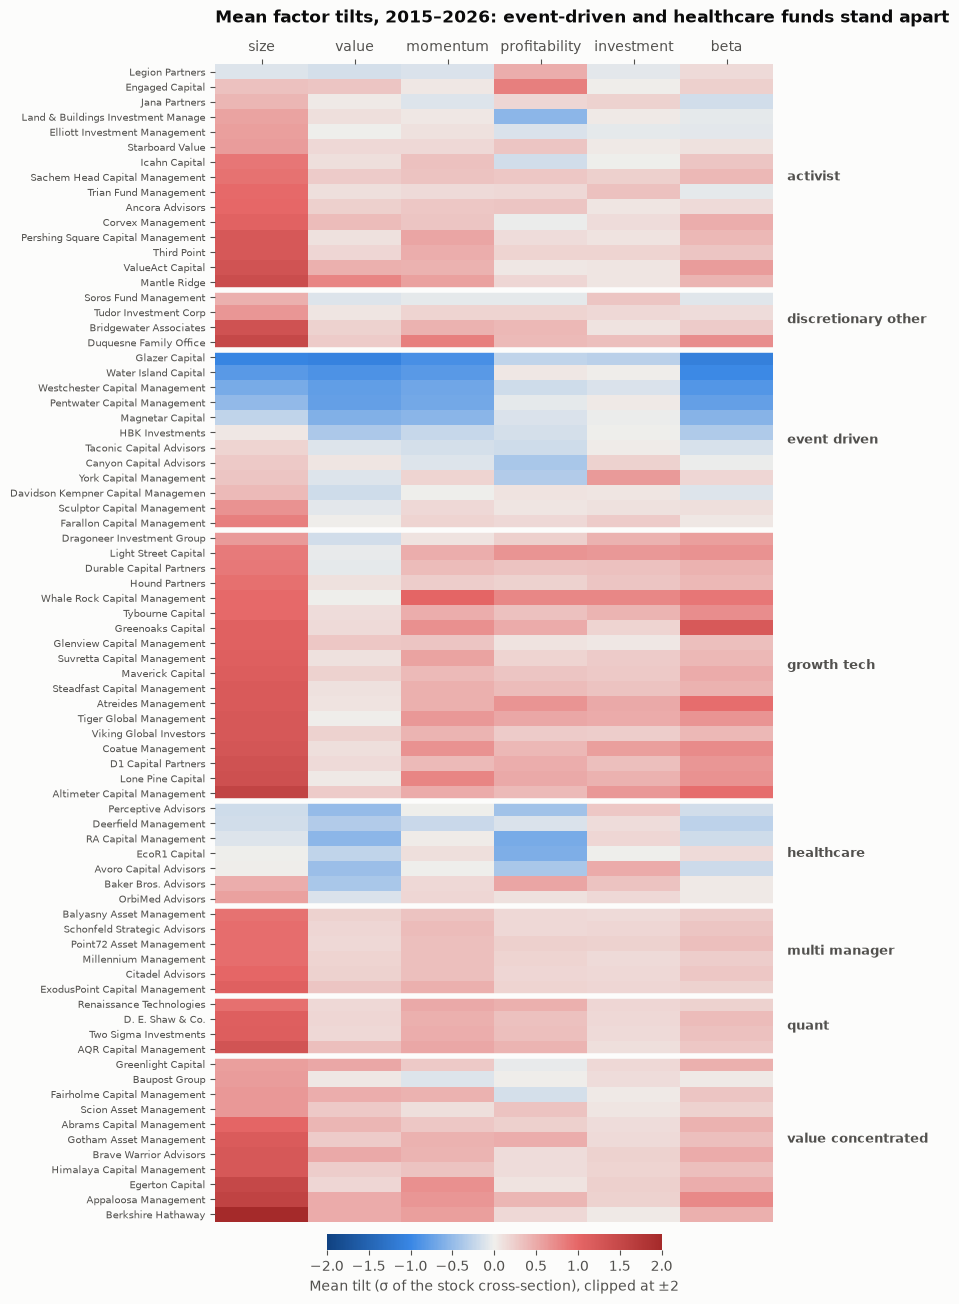

shape: (8, 7)
┌─────────────────────┬──────┬───────┬──────────┬───────────────┬────────────┬───────┐
│ style_guess         ┆ size ┆ value ┆ momentum ┆ profitability ┆ investment ┆ beta  │
│ ---                 ┆ ---  ┆ ---   ┆ ---      ┆ ---           ┆ ---        ┆ ---   │
│ str                 ┆ f64  ┆ f64   ┆ f64      ┆ f64           ┆ f64        ┆ f64   │
╞═════════════════════╪══════╪═══════╪══════════╪═══════════════╪════════════╪═══════╡
│ activist            ┆ 0.91 ┆ 0.16  ┆ 0.3      ┆ 0.17          ┆ 0.06       ┆ 0.23  │
│ discretionary_other ┆ 0.99 ┆ 0.13  ┆ 0.31     ┆ 0.28          ┆ 0.24       ┆ 0.2   │
│ event_driven        ┆ 0.13 ┆ -0.28 ┆ -0.19    ┆ -0.14         ┆ 0.03       ┆ -0.24 │
│ growth_tech         ┆ 1.13 ┆ 0.1   ┆ 0.47     ┆ 0.37          ┆ 0.39       ┆ 0.66  │
│ healthcare          ┆ -0.0 ┆ -0.38 ┆ 0.02     ┆ -0.38         ┆ 0.18       ┆ -0.16 │
│ multi_manager       ┆ 0.95 ┆ 0.2   ┆ 0.35     ┆ 0.19          ┆ 0.17       ┆ 0.27  │
│ quant               ┆ 1.13 

In [4]:
FACT = ["size", "value", "momentum", "profitability", "investment", "beta"]
tilts = (con.execute(f"""
    SELECT fund_id, any_value(fund_name) AS fund_name, {", ".join(f"avg(tilt_{f}) AS tilt_{f}" for f in FACT)}
    FROM fund_quarter WHERE n_positions > 0
    GROUP BY fund_id
""").pl().join(seed.select("fund_id", "style_guess"), on="fund_id", how="left")
          .sort("style_guess", "tilt_size"))
mat = np.clip(tilts.select([f"tilt_{f}" for f in FACT]).to_numpy().astype(float), -2, 2)

fig, ax = plt.subplots(figsize=(7.2, 15.5))
im = ax.imshow(mat, cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(FACT)), FACT, rotation=0)
ax.xaxis.tick_top()
ax.set_yticks(range(len(tilts)), [n[:34] for n in tilts["fund_name"]], fontsize=7.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
# style group separators and labels
styles = tilts["style_guess"].to_list()
starts = [0] + [i for i in range(1, len(styles)) if styles[i] != styles[i - 1]]
for k, s in enumerate(starts):
    end = starts[k + 1] if k + 1 < len(starts) else len(styles)
    if s:
        ax.axhline(s - 0.5, color=SURFACE, linewidth=4)
    ax.text(len(FACT) - 0.35, (s + end - 1) / 2, styles[s].replace("_", " "), va="center", ha="left",
            fontsize=9, color=INK2, fontweight="bold")
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.02, pad=0.01, shrink=0.6)
cb.set_label("Mean tilt (σ of the stock cross-section), clipped at ±2", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Mean factor tilts, 2015–2026: event-driven and healthcare funds stand apart", pad=30)
save(fig, "03_factor_tilts_heatmap.png")
plt.show()

print(tilts.group_by("style_guess").agg([pl.col(f"tilt_{f}").median().round(2).alias(f) for f in FACT])
      .sort("style_guess"))

**Reading.** Averaged over all 46 quarters, most funds are red on
size (style medians +0.9 to +1.2σ), the mechanical result of value-weighting
against an equal-weighted cross-section; the exceptions carry the information.
Event-driven funds are the clearest block: the merger-arbitrage shops (Glazer,
Water Island, Westchester, Pentwater) tilt small, low book-to-market, low
momentum and low beta, consistent with holding deal targets that move on deal
news rather than with the market. The style medians (value −0.28, momentum
−0.19, beta −0.24) are about half what the restated filings show, because
these funds often get confidential treatment for deal positions and disclose
them in amendments months later (8.6% of event-driven value; Davidson
Kempner 38%, Taconic 28%, HBK 15%). The tilts here use only what was public
at the original filing. Healthcare funds tilt low on value and
profitability (both −0.38σ), which is biotech; their momentum tilt is neutral
over the full history (+0.02σ) although it was +1.09σ in 2026Q2 alone, a
reminder that one quarter is not a style. Growth/tech has the highest beta
(+0.66σ), concentrated value the highest value tilt (+0.41σ, still modest),
and multi-managers and quants are nearly identical rows. Early-year tilts use
only priced holdings (68–77% of value before 2018, chart 5).

## 4. Pershing Square's portfolio over time

Over 46 quarters Pershing Square held about 30 names at 5% or more, too
many for stacked bars with one fixed colour each, so this is a heatmap:
one row per name that ever reached 5% of the long book, ordered by first
entry, shaded by weight. Both filer IDs are combined (see
`fund_book_decisions`); GOOG and GOOGL are combined as Alphabet, and the
old and new Canadian Pacific listings as CP.

saved docs/figures/04_pershing_square_over_time.png


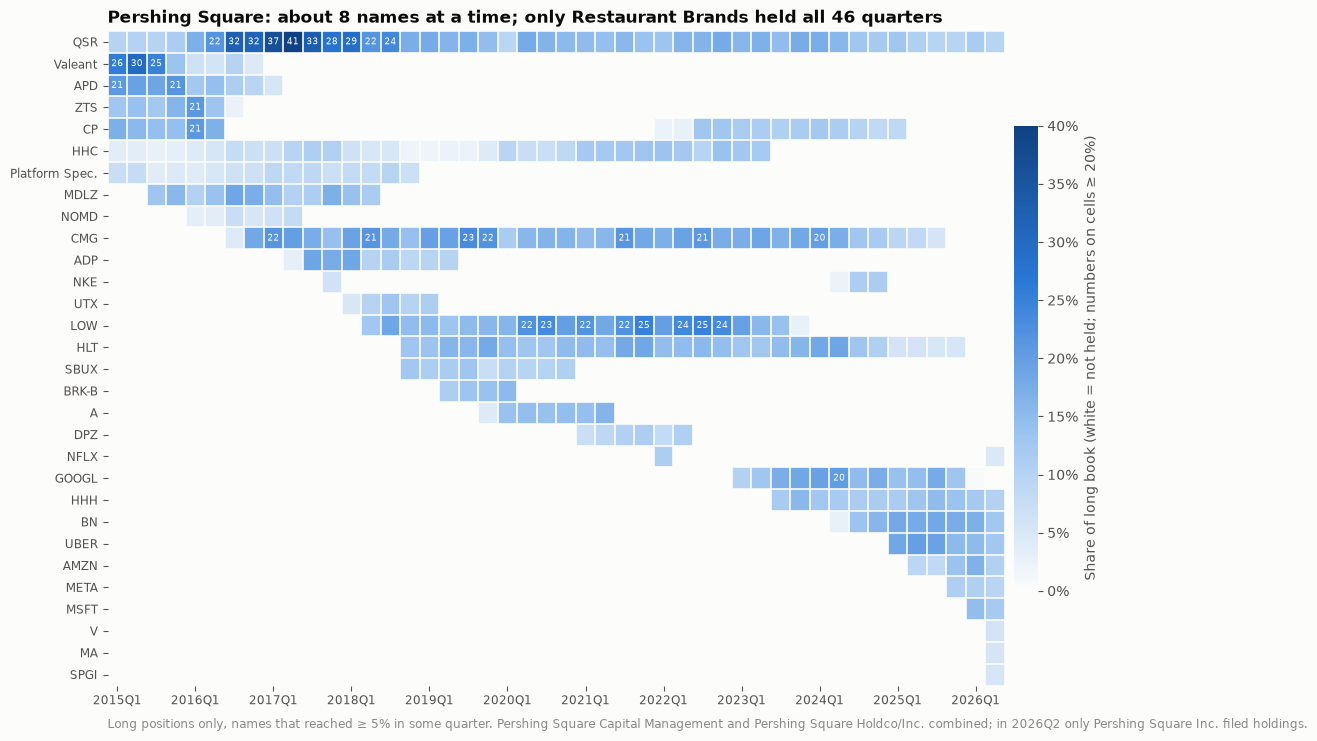

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 46.0     │
│ null_count ┆ 0.0      │
│ mean       ┆ 8.195652 │
│ std        ┆ 1.733584 │
│ min        ┆ 6.0      │
│ 25%        ┆ 7.0      │
│ 50%        ┆ 8.0      │
│ 75%        ┆ 9.0      │
│ max        ┆ 14.0     │
└────────────┴──────────┘
shape: (30, 5)
┌────────────────┬────────┬────────┬──────────┬───────┐
│ name           ┆ first  ┆ last   ┆ quarters ┆ peak  │
│ ---            ┆ ---    ┆ ---    ┆ ---      ┆ ---   │
│ str            ┆ str    ┆ str    ┆ u32      ┆ f64   │
╞════════════════╪════════╪════════╪══════════╪═══════╡
│ Platform Spec. ┆ 2015Q1 ┆ 2018Q4 ┆ 16       ┆ 0.097 │
│ ZTS            ┆ 2015Q1 ┆ 2016Q3 ┆ 7        ┆ 0.209 │
│ Valeant        ┆ 2015Q1 ┆ 2016Q4 ┆ 8        ┆ 0.299 │
│ APD            ┆ 2015Q1 ┆ 2017Q1 ┆ 9        ┆ 0.215 │
│ HHC            ┆ 2015Q1 ┆ 2023Q2 ┆ 34       ┆ 0.138 │
│ …              ┆ … 

In [5]:
LABELS = {"GOOG": "GOOGL", "CANADIAN PAC RY LTD": "CP", "UTXCHF": "UTX",
          "VALEANT PHARMACEUTICALS INTL": "Valeant", "PLATFORM SPECIALTY PRODS COR": "Platform Spec."}
ps = con.execute("""
    SELECT quarter, coalesce(symbol, name_of_issuer) AS name, sum(weight_long) AS w
    FROM positions WHERE fund_id = 'pershing_square_capital_management' AND NOT is_option
    GROUP BY ALL
""").pl().with_columns(pl.col("name").replace(LABELS)).group_by("quarter", "name").agg(pl.col("w").sum())
quarters = sorted(con.execute("SELECT DISTINCT quarter FROM fund_quarter").pl()["quarter"])
big = ps.filter(pl.col("w") >= 0.05)["name"].unique().to_list()
rows = (ps.filter(pl.col("name").is_in(big) & (pl.col("w") > 0))
        .group_by("name").agg(pl.col("quarter").min().alias("first"), pl.col("w").max().alias("peak"))
        .sort("first", "peak", descending=[False, True])["name"].to_list())
W = np.zeros((len(rows), len(quarters)))
for name, q, w in ps.filter(pl.col("name").is_in(rows)).select("name", "quarter", "w").iter_rows():
    W[rows.index(name), quarters.index(q)] = w

fig, ax = plt.subplots(figsize=(12, 8.5))
im = ax.imshow(np.where(W > 0, W, np.nan), cmap=SEQUENTIAL, vmin=0, vmax=0.4, aspect="auto",
               interpolation="nearest")
ax.set_yticks(range(len(rows)), rows, fontsize=8.5)
ax.set_xticks(range(0, len(quarters), 4), quarters[::4], fontsize=8.5)  # every Q1
ax.set_xticks(np.arange(-0.5, len(quarters)), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows)), minor=True)
ax.grid(False)
ax.grid(which="minor", color=SURFACE, linewidth=1.2)
ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(rows)):              # direct labels on the dominant positions
    for j in range(len(quarters)):
        if W[i, j] >= 0.2:
            ax.text(j, i, f"{W[i, j] * 100:.0f}", ha="center", va="center", fontsize=6.5, color=SURFACE)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("Share of long book (white = not held; numbers on cells ≥ 20%)", color=INK2)
cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
cb.outline.set_visible(False)
ax.set_title("Pershing Square: about 8 names at a time; only Restaurant Brands held all 46 quarters")
fig.text(0.125, 0.06, "Long positions only, names that reached ≥ 5% in some quarter. Pershing Square Capital "
         "Management and Pershing Square Holdco/Inc. combined; in 2026Q2 only Pershing Square Inc. filed holdings.",
         color=MUTED, fontsize=8.5)
save(fig, "04_pershing_square_over_time.png")
plt.show()

n_pos = con.execute("""
    SELECT quarter, n_positions, round(top10_weight, 3) AS top10 FROM fund_quarter
    WHERE fund_id = 'pershing_square_capital_management' ORDER BY quarter
""").pl()
print(n_pos["n_positions"].describe())
print(ps.filter(pl.col("name").is_in(rows)).group_by("name").agg(
    pl.col("quarter").min().alias("first"), pl.col("quarter").max().alias("last"),
    pl.len().alias("quarters"), pl.col("w").max().round(3).alias("peak")).sort("first"))

**Reading.** Pershing Square holds 6–14 long positions (median 8)
and keeps them for years. Restaurant Brands is the only name held in all 46
quarters, peaking at 41% of the book in 2017Q2. The rest comes in eras:
Valeant (26–30% in 2015, gone after 2016), Air Products, Zoetis and Canadian
Pacific in 2015–16; Chipotle from 2016Q4 to 2025Q4, often above 20%; ADP and
Mondelez around 2017–19; Lowe's (2018–23, up to 25%) and Hilton (2018–25);
Alphabet from 2023 (up to 20% in 2024Q2), sold down to under 1% in 2025Q4;
then Howard Hughes Holdings, Brookfield and Uber; and in 2026 Amazon, Meta,
Microsoft, Visa, Mastercard and S&P Global. Canadian Pacific shows a clean
exit and re-entry (2015–16, then 2021–25). Clear exits and initiations like
these are the events the next-quarter move model (Milestone 6) is meant to
predict.

## 5. Price coverage by year

Share of seed-fund value in priced classes (common, ADR, ETF, fund; the same
set as `prices.PRICED_CLASSES`) whose stock has a quarter-end price in
`stock_quarter`, pooled over the year's four quarters. A missing price also
means a missing `ret_next_q` label and missing return-based characteristics.

saved docs/figures/05_price_coverage_by_year.png


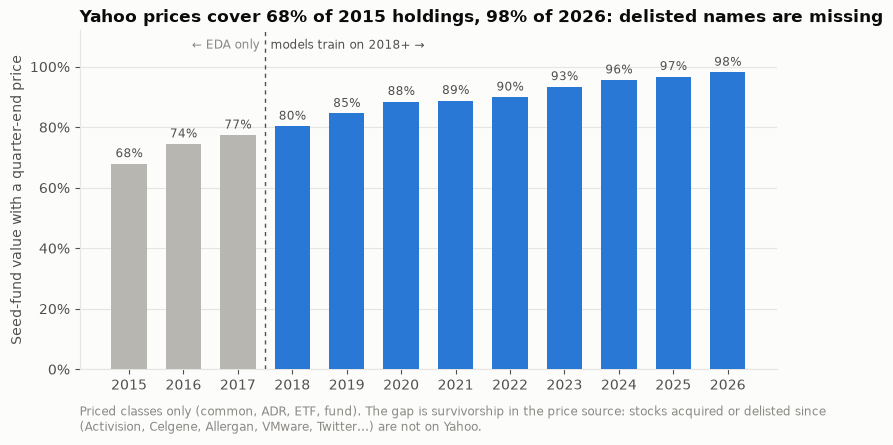

shape: (12, 3)
┌──────┬────────┬──────────┐
│ year ┆ priced ┆ labelled │
│ ---  ┆ ---    ┆ ---      │
│ i32  ┆ f64    ┆ f64      │
╞══════╪════════╪══════════╡
│ 2015 ┆ 0.679  ┆ 0.679    │
│ 2016 ┆ 0.745  ┆ 0.745    │
│ 2017 ┆ 0.774  ┆ 0.774    │
│ 2018 ┆ 0.803  ┆ 0.803    │
│ 2019 ┆ 0.845  ┆ 0.845    │
│ …    ┆ …      ┆ …        │
│ 2022 ┆ 0.899  ┆ 0.899    │
│ 2023 ┆ 0.934  ┆ 0.934    │
│ 2024 ┆ 0.956  ┆ 0.956    │
│ 2025 ┆ 0.967  ┆ 0.967    │
│ 2026 ┆ 0.982  ┆ 0.982    │
└──────┴────────┴──────────┘


In [6]:
PRICED_CLASSES = ("common", "adr", "etf", "fund")   # keep in sync with src/securities/prices.py
cov = con.execute(f"""
    SELECT left(p.quarter, 4)::INT AS year,
           sum(p.value_usd) FILTER (WHERE s.price IS NOT NULL) / sum(p.value_usd) AS priced,
           sum(p.value_usd) FILTER (WHERE s.ret_next_q IS NOT NULL) / sum(p.value_usd) AS labelled
    FROM seed_positions p JOIN security_master m USING (cusip)
    LEFT JOIN stock_quarter s ON s.cusip = p.cusip AND s.quarter = p.quarter
    WHERE m.security_class IN {PRICED_CLASSES}
    GROUP BY 1 ORDER BY 1
""").pl()
TRAIN_FROM = 2018

fig, ax = plt.subplots(figsize=(9, 4.4))
years, v = cov["year"].to_numpy(), cov["priced"].to_numpy()
ax.bar(years, v, width=0.65, color=[SERIES[0] if yr >= TRAIN_FROM else OTHER for yr in years], zorder=3)
for yr, x in zip(years, v):
    ax.text(yr, x + 0.012, f"{x:.0%}", ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.axvline(TRAIN_FROM - 0.5, color=INK2, linewidth=1, linestyle=(0, (3, 3)), zorder=4)
ax.text(TRAIN_FROM - 0.4, 1.05, f"models train on {TRAIN_FROM}+ →", fontsize=8.5, color=INK2, va="bottom")
ax.text(TRAIN_FROM - 0.6, 1.05, "← EDA only", fontsize=8.5, color=MUTED, va="bottom", ha="right")
ax.set_ylim(0, 1.12)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xticks(years, [str(y) for y in years])
ax.set_ylabel("Seed-fund value with a quarter-end price")
ax.grid(axis="x", visible=False)
ax.set_title("Yahoo prices cover 68% of 2015 holdings, 98% of 2026: delisted names are missing")
fig.text(0.125, -0.03, "Priced classes only (common, ADR, ETF, fund). The gap is survivorship in the price source: "
         "stocks acquired or delisted since (Activision, Celgene, Allergan, VMware, Twitter…) are not on Yahoo.",
         color=MUTED, fontsize=8.5, wrap=True)
save(fig, "05_price_coverage_by_year.png")
plt.show()
print(cov.with_columns(pl.col("priced", "labelled").round(3)))

**Reading.** Price coverage climbs from 68% of seed-fund value
in 2015 to 80% in 2018, 90% in 2022 and 98% in 2026. The missing value is not
random: it is stocks that were later acquired or delisted (Actavis/Allergan,
DirecTV, Celgene, Activision, VMware, Twitter…), which Yahoo no longer carries.
Returns, momentum, beta, market caps and the `ret_next_q` label (same coverage
as prices, second column above) are therefore survivor-skewed in the early
years: acquired targets, often sold at a premium, and failures drop out
together. So models will train and be evaluated on 2018 onward, where at
least 80% of value is priced; 2015–2017 stays in the data for description
and for features that don't need prices (position counts, turnover,
crowding). CRSP would close the gap if we get access
(see `docs/decisions.md`).